In [29]:
import json
from uuid import uuid4

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import MessagesState
from langgraph.prebuilt import ToolNode
from ragas import EvaluationDataset, aevaluate
from ragas import messages as ragas_messages
from ragas.dataset_schema import MultiTurnSample
from ragas.integrations.langgraph import convert_to_ragas_messages
from ragas.llms import LangchainLLMWrapper
from ragas.metrics import (
    AgentGoalAccuracyWithReference,
    FactualCorrectness,
    Faithfulness,
    LLMContextRecall,
    ToolCallAccuracy,
)
from ragas.run_config import RunConfig

C:\Users\amolj\AppData\Local\Temp\ipykernel_22104\2770868595.py:21: DeprecationWarning: Importing AgentGoalAccuracyWithReference from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import AgentGoalAccuracyWithReference
  from ragas.metrics import (
C:\Users\amolj\AppData\Local\Temp\ipykernel_22104\2770868595.py:21: DeprecationWarning: Importing FactualCorrectness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import FactualCorrectness
  from ragas.metrics import (
C:\Users\amolj\AppData\Local\Temp\ipykernel_22104\2770868595.py:21: DeprecationWarning: Importing Faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import (
C:\Users\amol

In [2]:
load_dotenv()

model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_completion_tokens=500,
    timeout=60,
    reasoning_effort="low",
    max_retries=2,
)

# Evaluator LLM for Ragas. Reasoning tokens count toward max_completion_tokens, so the
# cap must be generous or the judge's JSON output gets truncated (-> NaN scores).
# No temperature here: this model only accepts the default value.
eval_llm = ChatOpenAI(
    model=model,
    max_completion_tokens=4000,
    timeout=60,
    reasoning_effort="medium",
    max_retries=2,
    use_responses_api=False,
)

In [3]:
documents = [
    Document(
        page_content="Meta drops multimodal Llama 3.2 — here's why it's such a big deal",
        metadata={"company":"Meta", "topic": "llama"}
    ),
    Document(
        page_content="Chip giant Nvidia acquires OctoAI, a Seattle startup that helps companies run AI models",
        metadata={"company":"Nvidia", "topic": "acquisition"}
    ),
    Document(
        page_content="Google is bringing Gemini to all older Pixel Buds",
        metadata={"company":"Google", "topic": "gemini"}
    ),
    Document(
        page_content="The first Intel Battlmage GPU benchmarks have leaked",
        metadata={"company":"Intel", "topic": "gpu"}
    ),
    Document(
        page_content="Dell partners with Nvidia to accelerate AI adoption in telecoms",
        metadata={"company":"Dell", "topic": "partnership"}
    ),
]

ids = [str(uuid4()) for _ in documents]

In [4]:
documents

[Document(metadata={'company': 'Meta', 'topic': 'llama'}, page_content="Meta drops multimodal Llama 3.2 — here's why it's such a big deal"),
 Document(metadata={'company': 'Nvidia', 'topic': 'acquisition'}, page_content='Chip giant Nvidia acquires OctoAI, a Seattle startup that helps companies run AI models'),
 Document(metadata={'company': 'Google', 'topic': 'gemini'}, page_content='Google is bringing Gemini to all older Pixel Buds'),
 Document(metadata={'company': 'Intel', 'topic': 'gpu'}, page_content='The first Intel Battlmage GPU benchmarks have leaked'),
 Document(metadata={'company': 'Dell', 'topic': 'partnership'}, page_content='Dell partners with Nvidia to accelerate AI adoption in telecoms')]

In [5]:
ids

['cec05b50-cfaa-4da5-af65-d127ce91d2d2',
 '28e0b701-7aad-4dc8-9345-2e86ecd693f8',
 '54118937-32c2-409f-80af-69b490cc93c5',
 '8a513881-e082-4153-b79f-2979ed17c07e',
 'a7f76645-37c7-47dc-bbd5-f310589bc457']

In [6]:
embeddings_fn = OpenAIEmbeddings(model="text-embedding-3-large")

vector_store = Chroma(
    collection_name="ragas_demo",
    embedding_function=embeddings_fn,
)

vector_store.add_documents(documents=documents, ids=ids)
retriever = vector_store.as_retriever(search_kwargs={"k": 1})

In [7]:
prompt = ChatPromptTemplate.from_template(
    """Answer the question based only on the following context:
    {context}

    Question: {query}
    """
)

chain = prompt | llm | StrOutputParser()

In [8]:
def format_docs(relevant_docs):
    return "\n".join(doc.page_content for doc in relevant_docs)

In [9]:
query = "Who is partnering with Nvidia?"
relevant_docs = retriever.invoke(query)
chain.invoke({"context": format_docs(relevant_docs), "query": query})

'Dell.'

## Ragas Evaluation


In [10]:
sample_queries = [
    "What is Meta's latest development in AI?",
    "Which company did Nvidia acquire?",
    "What AI feature is Google adding to older Pixel Buds?",
    "What recent information has leaked about Intel GPUs?",
    "Which company did Dell partner with to accelerate AI adoption?"
]

In [11]:
expected_responses = [
    "Meta drops multimodal Llama 3.2 — here's why it's such a big deal",
    "Chip giant Nvidia acquires OctoAI, a Seattle startup that helps companies run AI models",
    "Google is bringing Gemini to all older Pixel Buds",
    "The first Intel Battlemage GPU benchmarks have leaked",
    "Dell partners with Nvidia to accelerate AI adoption in telecoms"
]

In [12]:
dataset = []

for query, reference in zip(sample_queries, expected_responses):
    relevant_docs = retriever.invoke(query)
    response = chain.invoke(
        {
            "context": format_docs(relevant_docs), 
            "query": query
        }
    )
    dataset.append(
        {
            "user_input": query,
            "retrieved_contexts": [doc.page_content for doc in relevant_docs],
            "response": response,
            "reference": reference,
        }
    )

evaluation_dataset = EvaluationDataset.from_list(dataset)

In [13]:
evaluation_dataset

EvaluationDataset(features=['user_input', 'retrieved_contexts', 'response', 'reference'], len=5)

In [14]:
# bypass_temperature: Ragas injects temperature=0.01, but this model only accepts the default.
# bypass_n: Ragas requests n > 1 completions; with this it sends n separate requests instead.
evaluator_llm = LangchainLLMWrapper(
    eval_llm,
    bypass_temperature=True,
    bypass_n=True,
)

# Use aevaluate (not evaluate): evaluate() patches the event loop with nest_asyncio,
# which breaks asyncio timeouts on Python 3.12+ ("Timeout should be used inside a task").
# NOTE: if evaluate() was ever run in this kernel, restart the kernel first; the
# nest_asyncio patch stays active until then.
result = await aevaluate(
    dataset=evaluation_dataset,
    metrics=[LLMContextRecall(), Faithfulness(), FactualCorrectness()],
    llm=evaluator_llm,
    # Ragas defaults to 10 retries per job with backoff, which makes failures look like a hang.
    run_config=RunConfig(timeout=180, max_retries=2, max_workers=4),
    raise_exceptions=True,
)

C:\Users\amolj\AppData\Local\Temp\ipykernel_22104\4021068219.py:3: DeprecationWarning: LangchainLLMWrapper is deprecated and will be removed in a future version. Use llm_factory instead: from openai import OpenAI; from ragas.llms import llm_factory; llm = llm_factory('gpt-4o-mini', client=OpenAI(api_key='...'))
  evaluator_llm = LangchainLLMWrapper(
C:\Users\amolj\AppData\Local\Temp\ipykernel_22104\4021068219.py:13: DeprecationWarning: aevaluate() is deprecated and will be removed in a future version. Use the @experiment decorator instead. See https://docs.ragas.io/en/latest/concepts/experiment/ for more information.
  result = await aevaluate(


Evaluating:   0%|          | 0/15 [00:00<?, ?it/s]

In [15]:
result

{'context_recall': 1.0000, 'faithfulness': 0.9000, 'factual_correctness(mode=f1)': 0.4280}

In [16]:
pokemon_types_map = {
    "pikachu": "electric",
    "eevee": "normal",
    "bulbasaur": "grass/poison",
    "squirtle": "water",
    "charizard": "fire/flying",
    "jigglypuff": "normal/fairy",
    "meowth": "normal",
    "psyduck": "water",
    "machamp": "fighting",
    "gengar": "ghost/poison",
    "alakazam": "psychic",
    "snorlax": "normal",
    "dragonite": "dragon/flying",
}

In [17]:
@tool
def get_pokemon_type(pokemon_name: str) -> str:
    """Fetches the type of the specified Pokémon.

    Args:
        pokemon_name : The name of the Pokémon (e.g., 'pikachu', 'charizard', 'eevee').

    Returns:
        str: The type(s) of the Pokémon.

    Raises:
        KeyError: If the specified Pokémon is not found in the data source.
    """
    try:
        pokemon_name = pokemon_name.lower().strip()
        if pokemon_name not in pokemon_types_map:
            raise KeyError(
                f"Pokémon '{pokemon_name}' not found. Available Pokémon: {', '.join(pokemon_types.keys())}"
            )
        return pokemon_types_map[pokemon_name]
    except Exception as e:
        raise Exception(f"Error fetching Pokémon type: {e!s}")

In [18]:
tools = [get_pokemon_type]

In [19]:
llm_with_tools = llm.bind_tools(tools)

In [20]:
def agent(state: MessagesState):
    ai_message = llm_with_tools.invoke(state["messages"])
    return {"messages": ai_message}

In [21]:
def router(state: MessagesState):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"

    return END

In [22]:
workflow = StateGraph(MessagesState)

workflow.add_node("agent", agent)
workflow.add_node("tools", ToolNode(tools))

workflow.add_edge(START, "agent")

workflow.add_conditional_edges(
    source="agent", 
    path=router, 
    path_map=["tools", END]
)

workflow.add_edge("tools", "agent")


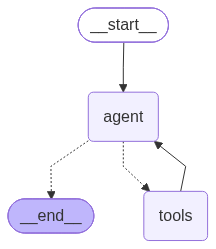

In [23]:
graph = workflow.compile()

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [24]:
result = graph.invoke(
    {"messages": [HumanMessage(content="What is the Gengar's type?")]}
)

In [25]:
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is the Gengar's type?
================================== Ai Message ==================================

[{'arguments': '{"pokemon_name":"gengar"}', 'call_id': 'call_37f02818506b40568be7b8da763755a0', 'name': 'get_pokemon_type', 'type': 'function_call', 'id': 'fc_04cb1c4d63f79c9a006b03e913cef887d0a4ed5ce3635cb7d2', 'status': 'completed'}]
Tool Calls:
  get_pokemon_type (call_37f02818506b40568be7b8da763755a0)
 Call ID: call_37f02818506b40568be7b8da763755a0
  Args:
    pokemon_name: gengar
================================= Tool Message =================================
Name: get_pokemon_type

ghost/poison
================================== Ai Message ==================================

[{'type': 'text', 'text': 'Gengar is a **Ghost/Poison-type** Pokémon.', 'annotations': [], 'id': 'msg_04cb1c4d63f79c9a006b03e916439c87d093578aa8de3122e8', 'phase': 'final_answer'}]


In [27]:
result["messages"]

[HumanMessage(content="What is the Gengar's type?", additional_kwargs={}, response_metadata={}, id='4c934f66-be57-4d07-80c5-229abfa6acce'),
 AIMessage(content=[{'arguments': '{"pokemon_name":"gengar"}', 'call_id': 'call_37f02818506b40568be7b8da763755a0', 'name': 'get_pokemon_type', 'type': 'function_call', 'id': 'fc_04cb1c4d63f79c9a006b03e913cef887d0a4ed5ce3635cb7d2', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_04cb1c4d63f79c9a006b03e9130fc887d0a4ffe60d9e9f2ed2', 'created_at': 1795418387.0, 'metadata': {}, 'model': 'gpt-5.6-sol', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-5.6-sol'}, id='resp_04cb1c4d63f79c9a006b03e9130fc887d0a4ffe60d9e9f2ed2', tool_calls=[{'name': 'get_pokemon_type', 'args': {'pokemon_name': 'gengar'}, 'id': 'call_37f02818506b40568be7b8da763755a0', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 112, 'output_tokens': 22, 'total_tok

### Converting to Ragas


In [30]:
def to_ragas_compatible(messages):
    """Adapt Responses-API messages to what ragas' LangGraph converter expects.

    With the Responses API, AIMessage.content is a list of blocks and the tool calls
    live in `message.tool_calls`. The converter wants a plain string for `content` and
    Chat-Completions-style tool calls in `additional_kwargs["tool_calls"]`.
    """
    adapted = []
    for message in messages:
        if isinstance(message, AIMessage):
            additional_kwargs = dict(message.additional_kwargs)
            if message.tool_calls:
                additional_kwargs["tool_calls"] = [
                    {
                        "id": tool_call["id"],
                        "type": "function",
                        "function": {
                            "name": tool_call["name"],
                            "arguments": json.dumps(tool_call["args"]),
                        },
                    }
                    for tool_call in message.tool_calls
                ]
            message = message.model_copy(
                update={"content": message.text, "additional_kwargs": additional_kwargs}
            )
        adapted.append(message)
    return adapted


ragas_trace = convert_to_ragas_messages(to_ragas_compatible(result["messages"]))

In [31]:
ragas_trace

[HumanMessage(content="What is the Gengar's type?", metadata=None, type='human'),
 AIMessage(content='', metadata=None, type='ai', tool_calls=[ToolCall(name='get_pokemon_type', args={'pokemon_name': 'gengar'})]),
 ToolMessage(content='ghost/poison', metadata=None, type='tool'),
 AIMessage(content='Gengar is a **Ghost/Poison-type** Pokémon.', metadata=None, type='ai', tool_calls=None)]

#### Evaluate Tool Use


In [32]:
sample = MultiTurnSample(
    user_input=ragas_trace,
    reference_tool_calls=[
        ragas_messages.ToolCall(
            name="get_pokemon_type", 
            args={"pokemon_name": "gengar"}
        )
    ],
)

In [33]:
scorer = ToolCallAccuracy()
scorer.llm = llm

In [34]:
await scorer.multi_turn_ascore(sample)

1.0

#### Evaluate Agent Goal


In [35]:
sample = MultiTurnSample(
    user_input=ragas_trace,
    reference="What is the Gengar's type?",
)

In [36]:
scorer = AgentGoalAccuracyWithReference()
scorer.llm = LangchainLLMWrapper(eval_llm, bypass_temperature=True, bypass_n=True)

C:\Users\amolj\AppData\Local\Temp\ipykernel_22104\2704454958.py:2: DeprecationWarning: LangchainLLMWrapper is deprecated and will be removed in a future version. Use llm_factory instead: from openai import OpenAI; from ragas.llms import llm_factory; llm = llm_factory('gpt-4o-mini', client=OpenAI(api_key='...'))
  scorer.llm = LangchainLLMWrapper(eval_llm, bypass_temperature=True, bypass_n=True)


In [37]:
await scorer.multi_turn_ascore(sample)

1.0